Perform topic modeling using LDA by optimizing the number of topics with coherence score evaluation, preprocessing text using TF-IDF filtering, and visualizing topic-word distributions using interactive tools like pyLDAvis.

In [1]:
import pandas as pd
import numpy as np

# Load previously saved preprocessed dataset
df = pd.read_pickle("saved_data/womens_clothing_final.pkl")
0
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nRequired column available:")
print("text_domain_cleaned:", "text_domain_cleaned" in df.columns)

print("\nMissing values:")
print(df["text_domain_cleaned"].isna().sum())

print("\nSample reviews:")
display(df["text_domain_cleaned"].head())

Dataset loaded successfully!
Dataset shape: (23483, 49)

Required column available:
text_domain_cleaned: True

Missing values:
0

Sample reviews:


0                                                                                                                                                                                                                                                                                                          absolutely wonderful silky sexy comfortable
1                                                                                                                                                             love dress soo pretty happened find store glad did because never ordered online because petite bought petite 5'8 love length me- hits just little knee definitely true midi truly petite
2    had such high hopes dress really wanted work initially ordered petite small usual size found outrageously small so small fact not zip reordered petite medium just ok overall top half comfortable fit nicely bottom half had very tight layer several somewhat cheap net layers in my opinion major design flaw net 

TF-IDF-based vocabulary filtering

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare documents
documents = (
    df["text_domain_cleaned"]
    .astype(str)
    .tolist()
)

# TF-IDF vectorization
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    min_df=5,
    max_df=0.85,
    max_features=10000,
    sublinear_tf=True
)

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("TF-IDF preprocessing completed!")
print("Document count:", tfidf_matrix.shape[0])
print("Vocabulary size:", tfidf_matrix.shape[1])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF preprocessing completed!
Document count: 23483
Vocabulary size: 4560
TF-IDF matrix shape: (23483, 4560)


Create Bag-of-Words matrix for LDA

In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from gensim.corpora import Dictionary

In [5]:
count_vectorizer = CountVectorizer(vocabulary=tfidf_vectorizer.vocabulary_, stop_words='english')

bow_matrix = count_vectorizer.fit_transform(documents)

# Prepare tokenized documents for coherence evaluation

selected_words = set(tfidf_vectorizer.vocabulary_.keys())

tokenized_docs = [
    [word for word in doc.split() if word in selected_words]
    for doc in documents
]

# Create Gensim dictionary
dictionary = Dictionary(tokenized_docs)

print("Bag-of-Words matrix created!")
print("Matrix shape:", bow_matrix.shape)
print("Vocabulary size:", len(count_vectorizer.vocabulary_))
print("Gensim dictionary size:", len(dictionary))
print("Total non-zero entries:", bow_matrix.nnz)
print("Example tokenized document:", tokenized_docs[0])

Bag-of-Words matrix created!
Matrix shape: (23483, 4560)
Vocabulary size: 4560
Gensim dictionary size: 4559
Total non-zero entries: 502397
Example tokenized document: ['absolutely', 'wonderful', 'silky', 'sexy', 'comfortable']


Optimize the number of LDA topics using Coherence Score

In [7]:
from gensim.models import LdaModel, CoherenceModel
from gensim import matutils
import time

In [10]:
topic_range = range(2, 11)

coherence_scores = []
lda_models = []

for num_topics in topic_range:
    start_time = time.time()
    # Train LDA model
    lda_model = LdaModel(
        corpus=matutils.Sparse2Corpus(bow_matrix, documents_columns=False),
        id2word=dictionary,
        num_topics=num_topics,
        random_state=42,
        passes=5,
        iterations=50,
        chunksize=2000,
        alpha="auto",
        eta="auto"
    )

    # Calculate coherence
    coherence_model = CoherenceModel(
        model=lda_model,
        texts=tokenized_docs,
        dictionary=dictionary,
        coherence="c_v",
        processes=1
    )

    coherence = coherence_model.get_coherence()

    lda_models.append(lda_model)
    coherence_scores.append(coherence)

    print(
        f"Topics: {num_topics} | "
        f"Coherence: {coherence:.4f} | "
        f"Time: {time.time() - start_time:.2f} seconds"
    )

    

Topics: 2 | Coherence: 0.3553 | Time: 48.63 seconds
Topics: 3 | Coherence: 0.4359 | Time: 59.88 seconds
Topics: 4 | Coherence: 0.4192 | Time: 79.27 seconds
Topics: 5 | Coherence: 0.4471 | Time: 105.10 seconds
Topics: 6 | Coherence: 0.4383 | Time: 173.99 seconds
Topics: 7 | Coherence: 0.4383 | Time: 173.78 seconds
Topics: 8 | Coherence: 0.4533 | Time: 168.08 seconds
Topics: 9 | Coherence: 0.4275 | Time: 171.26 seconds
Topics: 10 | Coherence: 0.4509 | Time: 174.76 seconds


In [9]:
from sklearn.feature_extraction.text import CountVectorizer

# Use only words present in Gensim dictionary
gensim_vocabulary = {
    word: word_id
    for word, word_id in dictionary.token2id.items()
}

# Rebuild CountVectorizer with matching word IDs
count_vectorizer = CountVectorizer(
    vocabulary=gensim_vocabulary,
    stop_words="english"
)

bow_matrix = count_vectorizer.fit_transform(documents)

print("Vocabulary mismatch fixed!")
print("Bag-of-Words shape:", bow_matrix.shape)
print("Dictionary size:", len(dictionary))
print("Vectorizer vocabulary size:", len(count_vectorizer.vocabulary_))
print("Maximum dictionary ID:", max(dictionary.token2id.values()))

Vocabulary mismatch fixed!
Bag-of-Words shape: (23483, 4559)
Dictionary size: 4559
Vectorizer vocabulary size: 4559
Maximum dictionary ID: 4558


Visualize coherence scores

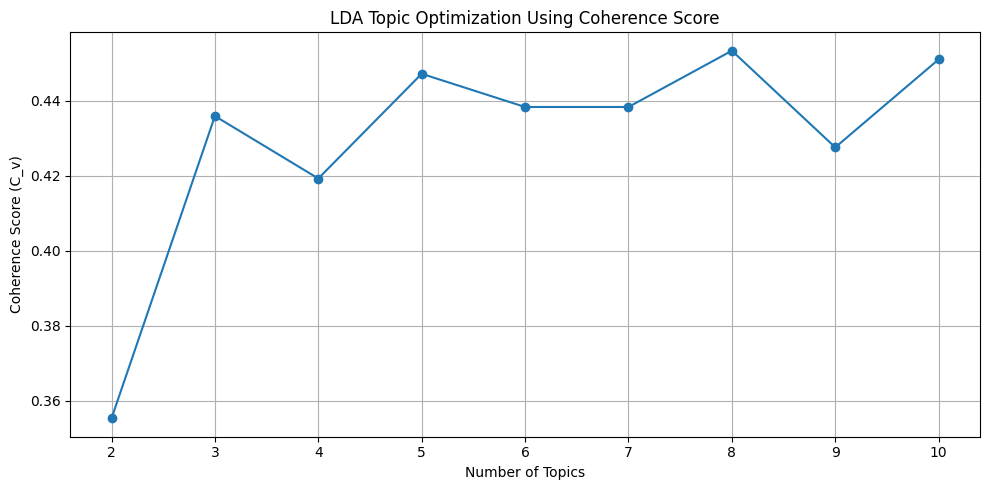

Optimal number of topics: 8


In [11]:
import matplotlib.pyplot as plt

coherence_results = pd.DataFrame({
    "Number of Topics": list(topic_range),
    "Coherence Score": coherence_scores
})

plt.figure(figsize=(10, 5))

plt.plot(
    coherence_results["Number of Topics"],
    coherence_results["Coherence Score"],
    marker="o"
)

plt.xticks(list(topic_range))
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score (C_v)")
plt.title("LDA Topic Optimization Using Coherence Score")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Optimal number of topics:", coherence_results.loc[
    coherence_results["Coherence Score"].idxmax(),
    "Number of Topics"
])

Inspect the optimal 8-topic model

In [13]:
optimal_index = list(topic_range).index(8)
best_lda_model = lda_models[optimal_index]

print("Optimal LDA model: 8 topics")
print("Coherence score:", coherence_scores[optimal_index])

for topic_id, topic_words in best_lda_model.print_topics(
    num_topics=8,
    num_words=10
):
    print(f"\nTopic {topic_id + 1}:")
    print(topic_words)

Optimal LDA model: 8 topics
Coherence score: 0.45326814953551564

Topic 1:
0.059*"x00d" + 0.034*"provided" + 0.017*"body" + 0.014*"arm" + 0.014*"suit" + 0.013*"shoulders" + 0.012*"arms" + 0.011*"fit" + 0.011*"holes" + 0.009*"athletic"

Topic 2:
0.050*"size" + 0.032*"small" + 0.022*"ordered" + 0.020*"fit" + 0.019*"large" + 0.015*"medium" + 0.015*"xs" + 0.014*"wear" + 0.013*"petite" + 0.013*"usually"

Topic 3:
0.029*"shirt" + 0.022*"color" + 0.022*"nice" + 0.020*"looks" + 0.018*"really" + 0.017*"like" + 0.014*"soft" + 0.013*"fabric" + 0.012*"white" + 0.012*"look"

Topic 4:
0.040*"waist" + 0.032*"dress" + 0.029*"skirt" + 0.019*"flattering" + 0.017*"length" + 0.014*"fits" + 0.012*"hips" + 0.012*"love" + 0.011*"fit" + 0.010*"bra"

Topic 5:
0.053*"pants" + 0.042*"jeans" + 0.036*"fit" + 0.022*"size" + 0.021*"pair" + 0.016*"love" + 0.016*"stretch" + 0.016*"great" + 0.015*"shorts" + 0.012*"length"

Topic 6:
0.040*"compliments" + 0.029*"wore" + 0.026*"price" + 0.025*"sale" + 0.024*"received" + 0

In [14]:
%pip install pyLDAvis

   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.6 MB 1.8 MB/s eta 0:00:02
   ---------------- ----------------------- 1.0/2.6 MB 2.2 MB/s eta 0:00:01
   ---------------- ----------------------- 1.0/2.6 MB 2.2 MB/s eta 0:00:01
   -------------------- ------------------- 1.3/2.6 MB 1.5 MB/s eta 0:00:01
   -------------------------------- ------- 2.1/2.6 MB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 2.6/2.6 MB 1.9 MB/s  0:00:01

   ---------------------------------------- 0/3 [funcy]
   ---------------------------------------- 0/3 [funcy]
   ---------------------------------------- 0/3 [funcy]
   ------------- -------------------------- 1/3 [numexpr]
   ------------- -------------------------- 1/3 [numexpr]
   ------------- -------------------------- 1/3 [numexpr]
   -------------------------- ------------- 2/3 [pyLDAvis]
   ----


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Generate interactive pyLDAvis visualization

In [16]:
from gensim import matutils

corpus = matutils.Sparse2Corpus(
    bow_matrix,
    documents_columns=False
)

print("Corpus rebuilt successfully!")
print("Documents:", len(corpus))
print("Dictionary size:", len(dictionary))

Corpus rebuilt successfully!
Documents: 23483
Dictionary size: 4559


In [18]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

pyLDAvis.enable_notebook()

lda_vis = gensimvis.prepare(
    best_lda_model,
    corpus,
    dictionary,
    sort_topics=False
)

pyLDAvis.display(lda_vis)

In [19]:
pyLDAvis.save_html(
    lda_vis,
    "lda_topic_visualization.html"
)

print("Visualization saved successfully!")

Visualization saved successfully!


### Conclusion – LDA Topic Modeling

Latent Dirichlet Allocation (LDA) was implemented to discover hidden topics and common themes in the Women's Clothing Reviews dataset containing 23,483 customer reviews.

Text preprocessing was performed using the previously cleaned review text. TF-IDF filtering was applied to select relevant vocabulary by removing common and rare terms. A count-based Bag-of-Words representation was subsequently created for LDA, as LDA is designed to work with word-frequency counts.

Multiple LDA models containing 2 to 10 topics were trained and evaluated using the Cᵥ coherence score. The model with 8 topics achieved the highest coherence score of **0.4533**, making it the best-performing model among the tested configurations.

The eight identified topics represented meaningful themes, including body measurements and fitting, size preferences, shirt and fabric characteristics, dresses and skirts, pants and jeans, purchasing experiences, clothing quality, and comfort.

The topics were further explored through an interactive visualization using **pyLDAvis**. It helped examine topic prevalence, similarities between topics, and the relevance of individual words within each topic.

Overall, LDA successfully identified several major discussion themes in customer reviews and provided useful insights into customer preferences, clothing fit, product quality, comfort, and purchasing experiences. However, some topics share related terms, and the coherence score indicates that the discovered topics are moderately interpretable rather than perfectly separated.